In [8]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr, L500_from_T500, Linj_from_L500
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
data, var = load_data_and_var()

In [3]:
all_nfws = generate_nfws_from_combined_dataset_werr(data, var)

In [4]:
nfws = [nfw for nfw in all_nfws if nfw.energies.is_virialized_gaspari]

In [5]:
test_nfw = nfws[0]

In [6]:
rmin = 0.001*test_nfw.R500
rmax = test_nfw.R500
rc=0.1*test_nfw.R500

In [41]:
Tbs = np.logspace(-8, 0)

In [30]:
dHeatdT=np.array([test_nfw.dheating_dT(rmin, rmax, rc, T) for T in Tbs])

In [27]:
dCooldT = np.array([test_nfw.dcooling_dT(rmin, rmax, T).value for T in Tbs])

In [51]:
#test_nfw.Tbs_norm*u.GeV.to(u.K, equivalencies=u.temperature_energy())
#Tbs_test = test_nfw.Tbs_norm*u.GeV.to(u.K, equivalencies=u.temperature_energy())*1e-6

In [52]:
#test_nfw.integrated_dm_cooling_rate(rmin, rmax, 1e-27, 1e-2, Tb=Tbs_test)

In [29]:
dDMCooldT= np.array([test_nfw.d_dmcooling_dT(rmin, rmax, 1e-27, 1e-2, T500=T).value for T in Tbs])

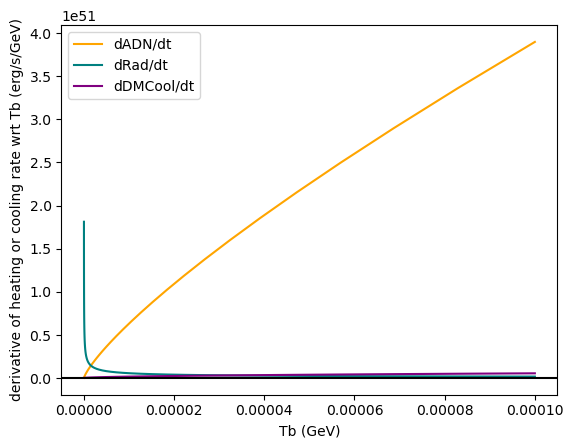

In [110]:
plt.plot(Tbs, dHeatdT, label='dADN/dt', color='orange')
plt.plot(Tbs, dCooldT, label='dRad/dt', color='teal')
plt.plot(Tbs, dDMCooldT, label='dDMCool/dt', color='purple')
plt.axhline(y=0, color='k', linestyle='-')
plt.xlabel('Tb (GeV)')
plt.ylabel('derivative of heating or cooling rate wrt Tb (erg/s/GeV)')
plt.legend()
#plt.xscale('log')
#plt.yscale('symlog')

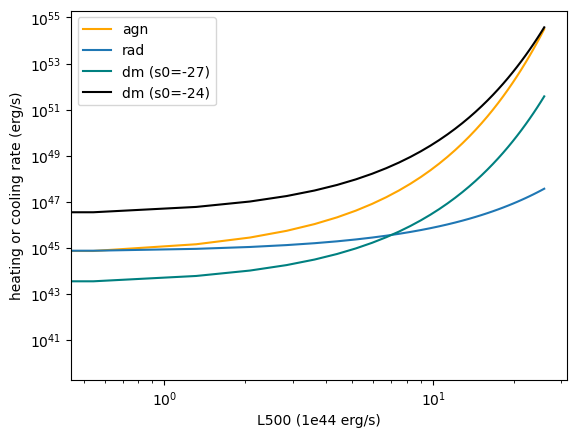

In [47]:
L500s = np.array([L500_from_T500(T) for T in Tbs])
plt.loglog(L500s, AGN_heating, color='orange', label="agn")
plt.loglog(L500s, rad_cooling, label='rad')
plt.loglog(L500s, dm_cooling, label='dm (s0=-27)', color='teal')
#plt.loglog(L500s, rad_cooling+dm_cooling, label='net cooling', color='purple')
plt.loglog(L500s, dm_cooling_24, label='dm (s0=-24)', color='black')

plt.xlabel('L500 (1e44 erg/s)')
plt.ylabel('heating or cooling rate (erg/s)')
plt.legend()

In [48]:
test_nfw.L500

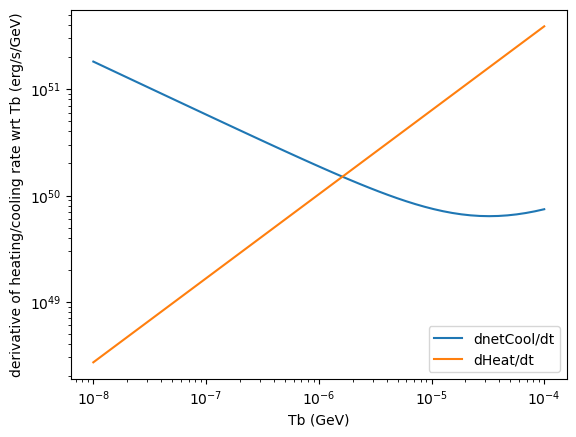

In [98]:
plt.loglog(Tbs, np.add(dCooldT, dDMCooldT), label='dnetCool/dt')
plt.loglog(Tbs, dHeatdT, label='dHeat/dt')

plt.xlabel('Tb (GeV)')
plt.ylabel('derivative of heating/cooling rate wrt Tb (erg/s/GeV)')
plt.legend()

In [33]:
test_nfw.Tbs_norm*u.GeV.to(u.K, equivalencies=u.temperature_energy())

array([0.12450988, 0.12908051, 0.14818355, 0.17003461, 0.1950031 ,
       0.22349954, 0.25597737, 0.29293364, 0.33490822, 0.38248105,
       0.43626646, 0.496904  , 0.56504452, 0.64133064, 0.72637041,
       0.82070324, 0.92475729, 1.03879823, 1.16286992, 1.29672889,
       1.43977574, 1.59098882, 1.74886675, 1.91138854, 2.07600058,
       2.23963961, 2.39879916, 2.5496431 , 2.68816491, 2.81038507,
       2.91257259, 2.99147175, 3.04451222, 3.06998112, 3.06713885,
       3.03626668, 2.97864165, 2.89644239, 2.79259665, 2.67058703,
       2.5342341 , 2.38747731, 2.23417182, 2.07791596, 1.92191908,
       1.76891399, 1.62111326, 1.48020461, 1.34737787, 1.        ])

Text(0, 0.5, 'Tb (GeV)')

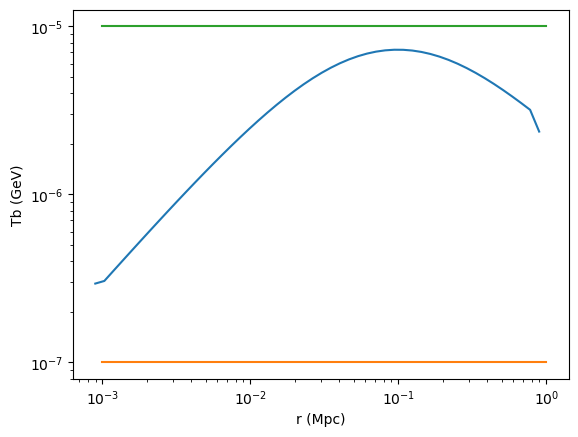

In [99]:
plt.loglog(test_nfw.rs_Mpc, test_nfw.Tbs)
plt.loglog([0.001, 1], [1e-7, 1e-7])
plt.loglog([0.001, 1], [1e-5, 1e-5])
plt.xlabel('r (Mpc)')
plt.ylabel('Tb (GeV)')

In [42]:
AGN_heating = np.array([test_nfw.total_heating_rate(rmin, rmax, rc, Linj=Linj_from_L500(L500_from_T500(T))) for T in Tbs])

In [43]:
rad_cooling = np.array([test_nfw.total_cooling_rate(rmin,
                                             rmax, 
                                             Tb=(test_nfw.Tbs_norm*u.GeV.to(u.K, equivalencies=u.temperature_energy())*T), 
                                             vol_rate='gfe').value for T in Tbs])

In [44]:
#dDMCooldT= np.array([test_nfw.d_dmcooling_dT(rmin, rmax, 1e-27, 1e-2, T500=T).value for T in Tbs])
dm_cooling= np.array([test_nfw.integrated_dm_cooling_rate(rmin, rmax, 1e-27, 1e-2, Tb=(test_nfw.Tbs_norm*u.GeV.to(u.K, equivalencies=u.temperature_energy())*T)).value for T in Tbs])

#integrated_dm_cooling_rate(self, rmin, rmax, s0, m_chi, num = 50, n=0, f_chi=1, m_psi=0.1*u.GeV, Tb=None)

In [45]:
dm_cooling_24= np.array([test_nfw.integrated_dm_cooling_rate(rmin, 
                                                             rmax, 
                                                             1e-24, 
                                                             1e-2, 
                                                             Tb=(test_nfw.Tbs_norm*u.GeV.to(u.K, equivalencies=u.temperature_energy())*T)).value for T in Tbs])

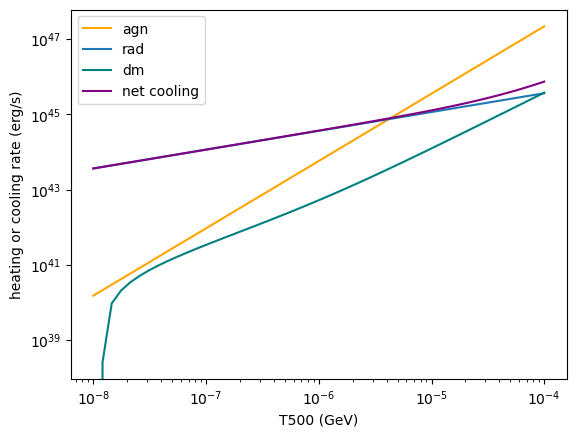

In [24]:
plt.loglog(Tbs, AGN_heating, color='orange', label="agn")
plt.loglog(Tbs, rad_cooling, label='rad')
plt.loglog(Tbs, dm_cooling, label='dm', color='teal')
plt.loglog(Tbs, rad_cooling+dm_cooling, label='net cooling', color='purple')
plt.xlabel('T500 (GeV)')
plt.ylabel('heating or cooling rate (erg/s)')
plt.legend()